# intentaremos ver, cargar y analizar un dt de audio

In [1]:
# Manejo de directorios y rutas
import os

# Computación numérica y manejo de matrices
import numpy as np

# Manejo y preprocesamiento de datos
import pandas as pd

# Librerías para graficación
from matplotlib import pyplot

# Mostrar gráficos dentro del cuadernillo
%matplotlib inline
import matplotlib.pyplot as plt

import random

import librosa

## cargamos el csv del dt de audio

In [3]:
metadata_us8k = pd.read_csv("dt_au/urbansound8k/UrbanSound8K.csv")
print(metadata_us8k.shape)
metadata_us8k.head()

(8732, 8)


,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.0,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.5,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.5,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.0,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.5,72.500000,1,5,2,children_playing


In [4]:
print(metadata_us8k["class"].value_counts())

class
dog_bark            1000
children_playing    1000
air_conditioner     1000
street_music        1000
engine_idling       1000
jackhammer          1000
drilling            1000
siren                929
car_horn             429
gun_shot             374
Name: count, dtype: int64


In [13]:
def extraer_features(path_archivo):
    y, sr = librosa.load(path_archivo)   # <-- quitamos res_type="kaiser_fast"
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
    mfccs_mean = np.mean(mfccs.T, axis=0)
    return mfccs_mean

In [14]:
features_us8k = []
# Apuntamos a la carpeta dt_au
audio_path_us8k = "dt_au/urbansound8k" 

for index, row in metadata_us8k.iterrows():
    fold_us8k = f"fold{row['fold']}"
    file_path_us8k = os.path.join(audio_path_us8k, fold_us8k, row["slice_file_name"])

    try:
        mfccs_us8k = extraer_features(file_path_us8k)
        features_us8k.append([mfccs_us8k, row["classID"], row["fold"]])
    except Exception as e:
        print(f"Error en {file_path_us8k}: {e}")

    if not (index + 1) % 500:
        print(f"Procesados {index + 1}/{len(metadata_us8k)}")

print("Extracción completa")

Procesados 500/8732
Procesados 1000/8732
Procesados 1500/8732
Procesados 2000/8732
Procesados 2500/8732
Procesados 3000/8732
Procesados 3500/8732


c:\Users\USUARIO\Desktop\ia_davalos\practicas\.venv\Lib\site-packages\librosa\core\spectrum.py:3004: UserWarning: n_fft=2048 is too large for input signal of length=1323
  stft(


Procesados 4000/8732
Procesados 4500/8732
Procesados 5000/8732
Procesados 5500/8732
Procesados 6000/8732
Procesados 6500/8732
Procesados 7000/8732
Procesados 7500/8732
Procesados 8000/8732


c:\Users\USUARIO\Desktop\ia_davalos\practicas\.venv\Lib\site-packages\librosa\core\spectrum.py:3004: UserWarning: n_fft=2048 is too large for input signal of length=1103
  stft(
c:\Users\USUARIO\Desktop\ia_davalos\practicas\.venv\Lib\site-packages\librosa\core\spectrum.py:3004: UserWarning: n_fft=2048 is too large for input signal of length=1523
  stft(


Procesados 8500/8732
Extracción completa


In [15]:
print(len(features_us8k))
print(len(metadata_us8k))

8732
8732


In [16]:
features_df_us8k = pd.DataFrame(features_us8k, columns=["feature", "classID", "fold"])
features_df_us8k.to_pickle("features_us8k.pkl")   # para recargar rápido después con pd.read_pickle
features_df_us8k.head()

,feature,classID,fold
0,"[-211.93698, 62.581207, -122.81315, -60.745293...",3,5
1,"[-417.0052, 99.336624, -42.995586, 51.073326, ...",2,5
2,"[-452.39316, 112.36253, -37.57807, 43.195866, ...",2,5
3,"[-406.47922, 91.1966, -25.043556, 42.78452, 11...",2,5
4,"[-439.63867, 103.86224, -42.658783, 50.690277,...",2,5


In [ ]:
X_us8k = np.array(features_df_us8k["feature"].tolist())
y_us8k = np.array(features_df_us8k["classID"].tolist())
fold_us8k = np.array(features_df_us8k["fold"].tolist())

print("X shape:", X_us8k.shape)  
print("y shape:", y_us8k.shape)

X shape: (8732, 40)
y shape: (8732,)


In [ ]:
train_mask_us8k = fold_us8k <= 8
val_mask_us8k = fold_us8k == 9
test_mask_us8k = fold_us8k == 10

X_train_us8k, y_train_us8k = X_us8k[train_mask_us8k], y_us8k[train_mask_us8k]
X_val_us8k, y_val_us8k = X_us8k[val_mask_us8k], y_us8k[val_mask_us8k]
X_test_us8k, y_test_us8k = X_us8k[test_mask_us8k], y_us8k[test_mask_us8k]

print("Train:", X_train_us8k.shape)
print("Val:", X_val_us8k.shape)
print("Test:", X_test_us8k.shape)

Train: (7079, 40)
Val: (816, 40)
Test: (837, 40)


In [19]:
def featureNormalize(X):

    X_norm = X.copy()

    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)

    X_norm = (X - mu) / sigma

    return X_norm, mu, sigma

In [65]:
X_train_us8k, mu, sigma = featureNormalize(X_train_us8k)

X_val_us8k = (X_val_us8k - mu) / sigma
X_test_us8k = (X_test_us8k - mu) / sigma

In [21]:
import torch

X_train_us8k_t = torch.tensor(
    X_train_us8k,
    dtype=torch.float32
).cuda()

X_test_us8k_t = torch.tensor(
    X_test_us8k,
    dtype=torch.float32
).cuda()

y_train_us8k_t = torch.tensor(
    y_train_us8k,
    dtype=torch.long
).cuda()

y_test_us8k_t = torch.tensor(
    y_test_us8k,
    dtype=torch.long
).cuda()

X_val_us8k_t = torch.tensor(
    X_val_us8k,
    dtype=torch.float32
).cuda()

y_val_us8k_t = torch.tensor(
    y_val_us8k,
    dtype=torch.long
).cuda()

In [55]:
D_in, H1, D_out = 40, 150, 10
model = torch.nn.Sequential(
torch.nn.Linear(D_in, H1),
torch.nn.ReLU(),
torch.nn.Dropout(0.2),
torch.nn.Linear(H1, D_out),
).cuda()

criterion = torch.nn.CrossEntropyLoss()


optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

epochs = 2000
log_each = 10

l = []
val_l = []         

best_val_loss = float("inf")
patience = 500                 
step = 0                       

model.train()

for e in range(1, epochs + 1):

    model.train()             

    
    y_pred = model(X_train_us8k_t)

   
    loss_emnist = criterion(
        y_pred,
        y_train_us8k_t
    )

    l.append(loss_emnist.item())

    
    optimizer.zero_grad()

    
    loss_emnist.backward()


    optimizer.step()

   
    model.eval()
    with torch.no_grad():
        val_logits_emnist = model(X_val_us8k_t)
        val_loss_emnist = criterion(
            val_logits_emnist,
            y_val_us8k_t
        )
    val_l.append(val_loss_emnist.item())

    if val_loss_emnist.item() < best_val_loss:
        best_val_loss = val_loss_emnist.item()
        torch.save(model.state_dict(), "ckpt_exa_us8k.pt")
        step = 0
    else:
        step += 1

    if step > patience:
        print(f"Early stopping en epoch {e} (sin mejora en {patience} epochs)")
        break
    

    if not e % log_each:
        print(
            f"Epoch {e}/{epochs} "
            f"Loss {loss_emnist.item():.5f} "
            f"Val_loss {val_loss_emnist.item():.5f}" 
        )

model.load_state_dict(torch.load("ckpt_exa_us8k.pt"))

Epoch 10/2000 Loss 2.30612 Val_loss 2.33705
Epoch 20/2000 Loss 2.28331 Val_loss 2.31661
Epoch 30/2000 Loss 2.25834 Val_loss 2.29676
Epoch 40/2000 Loss 2.23827 Val_loss 2.27744
Epoch 50/2000 Loss 2.21648 Val_loss 2.25867
Epoch 60/2000 Loss 2.19634 Val_loss 2.24031
Epoch 70/2000 Loss 2.17681 Val_loss 2.22234
Epoch 80/2000 Loss 2.15534 Val_loss 2.20466
Epoch 90/2000 Loss 2.13725 Val_loss 2.18729
Epoch 100/2000 Loss 2.11394 Val_loss 2.17023
Epoch 110/2000 Loss 2.09442 Val_loss 2.15336
Epoch 120/2000 Loss 2.07891 Val_loss 2.13672
Epoch 130/2000 Loss 2.05978 Val_loss 2.12028
Epoch 140/2000 Loss 2.03972 Val_loss 2.10405
Epoch 150/2000 Loss 2.01890 Val_loss 2.08805
Epoch 160/2000 Loss 2.00413 Val_loss 2.07226
Epoch 170/2000 Loss 1.98286 Val_loss 2.05664
Epoch 180/2000 Loss 1.96428 Val_loss 2.04122
Epoch 190/2000 Loss 1.94957 Val_loss 2.02593
Epoch 200/2000 Loss 1.93198 Val_loss 2.01087
Epoch 210/2000 Loss 1.91387 Val_loss 1.99601
Epoch 220/2000 Loss 1.89509 Val_loss 1.98132
Epoch 230/2000 Loss

<All keys matched successfully>

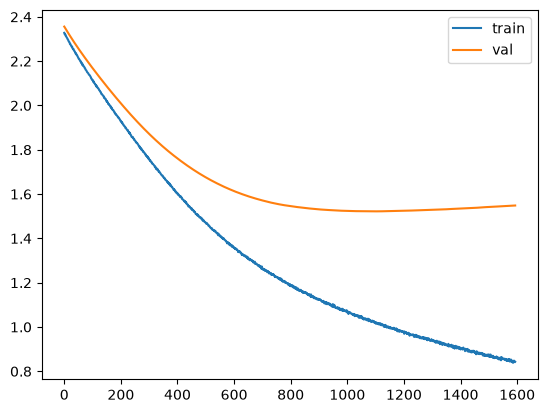

In [56]:
plt.plot(l, label="train")
plt.plot(val_l, label="val")
plt.legend()

In [57]:
from sklearn.metrics import accuracy_score

def evaluate(x):

    model.eval()

    logits = model(x)

    probabilidades = torch.softmax(logits, dim=1)

    predicciones = torch.argmax(
        probabilidades,
        dim=1
    )

    return predicciones

In [58]:
y_pred = evaluate(
    X_test_us8k_t
)

accuracy = accuracy_score(
    y_test_us8k_t.cpu().numpy(),
    y_pred.cpu().numpy()
)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 48.63%


# metricas

matriz de confucion

In [59]:
from sklearn.metrics import confusion_matrix

cm_emnist = confusion_matrix(
    y_test_us8k_t.cpu().numpy(),
    y_pred.cpu().numpy()
)

print(cm_emnist)

[[45  0 20  0  0  2  0 17  0 16]
 [ 3 24  0  0  1  0  0  1  0  4]
 [ 1  0 54 14  3  0  3  0  9 16]
 [ 7  0  9 56 11  3  1  5  2  6]
 [ 0  0  6  0 37  6  0 23  8 20]
 [ 8  0 28  0  0 49  0  8  0  0]
 [ 1  0  7 18  0  0  5  0  1  0]
 [ 0  0  0  0 51  0  0 45  0  0]
 [19  0  9  4  1  1  0  4 45  0]
 [19  2  6  1 10  4  0  6  5 47]]


precicion y recall

In [60]:
from sklearn.metrics import precision_score, recall_score

precision_emnist = precision_score(
    y_test_us8k_t.cpu().numpy(),
    y_pred.cpu().numpy(),
    average="macro"
)
recall_emnist = recall_score(
    y_test_us8k_t.cpu().numpy(),
    y_pred.cpu().numpy(),
    average="macro"
)

precision_emnist, recall_emnist

(0.5471466826243252, 0.481132312240163)

f1_score

In [61]:
from sklearn.metrics import f1_score

f1_emnist = f1_score(
    y_test_us8k_t.cpu().numpy(),
    y_pred.cpu().numpy(),
    average="macro"
)

f1_emnist

0.4976073247762285

curva ROCK

In [62]:
from sklearn.metrics import roc_auc_score

model.eval()
with torch.no_grad():
    logits_emnist = model(X_test_us8k_t)
    probabilidades_emnist = torch.softmax(logits_emnist, dim=1)

auc_emnist = roc_auc_score(
    y_test_us8k_t.cpu().numpy(),
    probabilidades_emnist.cpu().numpy(),
    multi_class="ovr",
    average="macro"
)

auc_emnist

0.8530568636629852

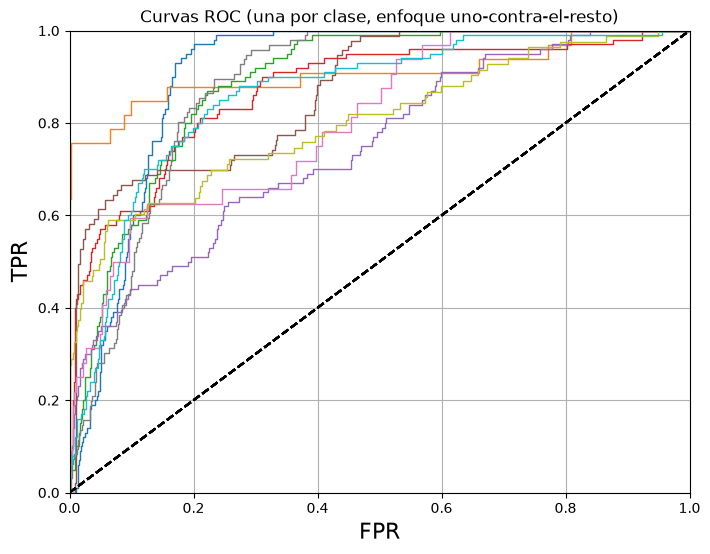

In [63]:
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
import numpy as np


y_test_bin_emnist = label_binarize(
    y_test_us8k_t.cpu().numpy(),
    classes=np.arange(D_out)
)


def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=1, label=label)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.axis([0, 1, 0, 1])
    plt.xlabel('FPR', fontsize=16)
    plt.ylabel('TPR', fontsize=16)
    plt.grid(True)

plt.figure(figsize=(8, 6))


for clase in range(D_out):
    fpr, tpr, _ = roc_curve(
        y_test_bin_emnist[:, clase],
        probabilidades_emnist.cpu().numpy()[:, clase]
    )
    plot_roc_curve(fpr, tpr)

plt.title("Curvas ROC (una por clase, enfoque uno-contra-el-resto)")
plt.show()

In [66]:
# Reconstruimos qué fila de metadata corresponde a cada posición de X_test_us8k
# (mismo orden porque fold_us8k se armó iterando metadata_us8k en orden)
metadata_test_us8k = metadata_us8k[metadata_us8k["fold"] == 10].reset_index(drop=True)

# Diccionario classID -> nombre real de la clase
id_a_clase = dict(zip(metadata_us8k["classID"], metadata_us8k["class"]))

In [70]:
import random
import IPython.display as ipd

ix = random.randint(0, len(X_test_us8k_t) - 1)

clase_real_id = y_test_us8k_t.cpu().numpy()[ix]
clase_pred_id = y_pred.cpu().numpy()[ix]

print(f"Clase real:      {id_a_clase[clase_real_id]} (id {clase_real_id})")
print(f"Clase predicha:  {id_a_clase[clase_pred_id]} (id {clase_pred_id})")

# Reconstruimos la ruta del archivo original para poder escucharlo
fila = metadata_test_us8k.iloc[ix]
ruta_audio = os.path.join(
    "dt_au/urbansound8k",
    f"fold{fila['fold']}",
    fila["slice_file_name"]
)

ipd.Audio(ruta_audio)

Clase real:      siren (id 8)
Clase predicha:  dog_bark (id 3)


In [71]:
resultados = pd.DataFrame({
    "real": [id_a_clase[c] for c in y_test_us8k_t.cpu().numpy()],
    "predicho": [id_a_clase[c] for c in y_pred.cpu().numpy()]
})

# Filtra solo los que el modelo falló
errores_us8k = resultados[resultados["real"] != resultados["predicho"]]
print(f"Total de errores: {len(errores_us8k)} de {len(resultados)}")
errores_us8k.head(10)

Total de errores: 430 de 837


,real,predicho
0,car_horn,street_music
1,car_horn,street_music
2,car_horn,street_music
3,car_horn,street_music
4,car_horn,drilling
9,children_playing,dog_bark
10,children_playing,dog_bark
11,children_playing,drilling
12,children_playing,drilling
13,children_playing,dog_bark
